In [1]:

print("Welcome to my UK Road Safety Analytics project!")
print("My goal is to analyse road collisions in Great Britain.")


Welcome to my UK Road Safety Analytics project!
My goal is to analyse road collisions in Great Britain.


In [2]:

import pandas as pd

# Find the CSV you uploaded
import glob

csv_files = glob.glob("/content/*.csv")
print("Available CSV files:", csv_files)

if not csv_files:
    raise FileNotFoundError(
        "Please upload the collision CSV in Colab first."
    )

# Load the road collision data
df = pd.read_csv(csv_files[0], low_memory=False)

# Display the first five rows
df.head()


Available CSV files: ['/content/dft-road-casualty-statistics-collision-2025.csv']


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,...,-1,0,2,3,2,E01012468,3,1,0.0,1.0
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,...,-1,0,2,1,1,E01012551,3,1,0.0,1.0


In [3]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))


Number of rows: 101525
Number of columns: 44

Column names:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location

In [4]:

# Make a working copy of the original data
clean_df = df.copy()

# Check duplicate collision records
print("Duplicate collision IDs:",
      clean_df.duplicated(
          subset=["collision_index"]
      ).sum())

# Remove duplicate records if they exist
clean_df = clean_df.drop_duplicates(
    subset=["collision_index"]
)

# Check severity categories
print(clean_df["collision_severity"].value_counts(
    dropna=False
))


Duplicate collision IDs: 0
collision_severity
3    74881
2    25191
1     1453
Name: count, dtype: int64


In [5]:

severity_labels = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

clean_df["severity_label"] = (
    pd.to_numeric(
        clean_df["collision_severity"],
        errors="coerce"
    ).map(severity_labels)
)

# Only use recognised severity categories
clean_df = clean_df.dropna(
    subset=["severity_label"]
).copy()

print(clean_df["severity_label"].value_counts())


severity_label
Slight     74881
Serious    25191
Fatal       1453
Name: count, dtype: int64


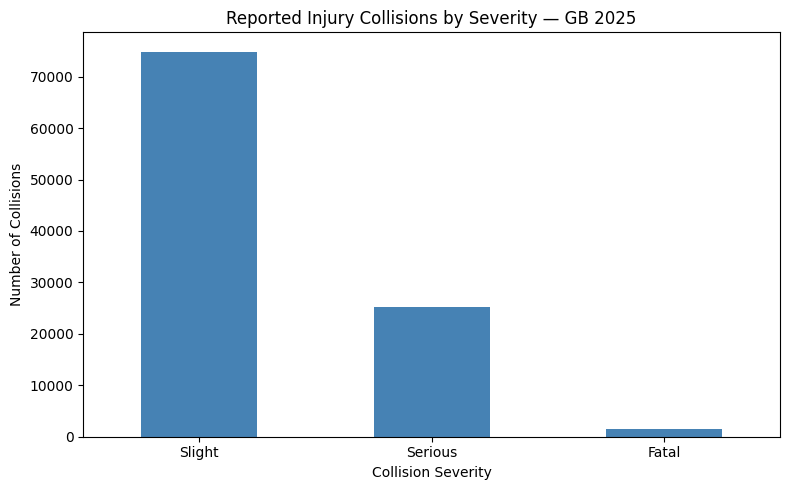

In [6]:

import matplotlib.pyplot as plt

severity_counts = (
    clean_df["severity_label"]
    .value_counts()
    .reindex(["Slight", "Serious", "Fatal"], fill_value=0)
)

severity_counts.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Reported Injury Collisions by Severity — GB 2025")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("severity_distribution.png", dpi=150)
plt.show()


In [7]:

# Create a simple indicator:
# 1 = Fatal or serious, 0 = Slight

clean_df["severe_collision"] = (
    clean_df["severity_label"].isin(
        ["Fatal", "Serious"]
    ).astype(int)
)

# Calculate severity percentage for each lighting code
light_results = (
    clean_df.groupby("light_conditions")
    .agg(
        collisions=("severe_collision", "size"),
        severe_count=("severe_collision", "sum"),
        severe_rate=("severe_collision", "mean")
    )
    .reset_index()
)

# Convert fraction into a percentage
light_results["severe_rate_pct"] = (
    light_results["severe_rate"] * 100
)

# Show groups with at least 100 recorded collisions
light_results = light_results[
    light_results["collisions"] >= 100
].sort_values("severe_rate_pct", ascending=False)

print(light_results)


   light_conditions  collisions  severe_count  severe_rate  severe_rate_pct
4                 6        5682          2062     0.362900        36.290039
3                 5         720           208     0.288889        28.888889
2                 4       20705          5554     0.268244        26.824439
1                 1       72814         18444     0.253303        25.330294
5                 7        1588           372     0.234257        23.425693


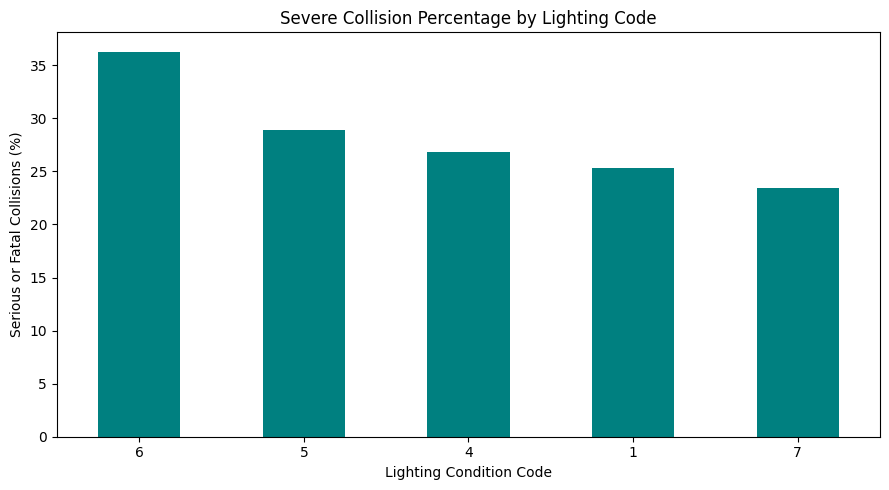

In [8]:

light_results.plot(
    x="light_conditions",
    y="severe_rate_pct",
    kind="bar",
    legend=False,
    color="teal",
    figsize=(9, 5)
)

plt.title("Severe Collision Percentage by Lighting Code")
plt.xlabel("Lighting Condition Code")
plt.ylabel("Serious or Fatal Collisions (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("lighting_severity.png", dpi=150)
plt.show()
